<a href="https://colab.research.google.com/github/samar8x/CVIP_Project/blob/main/Notebooks/05_Visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 — Final Visualizations


This notebook generates the final quantitative and qualitative visualizations from the corrected Cityscapes and ACDC evaluation results.

### Important interpretation

The Cityscapes-to-ACDC figures are **cross-dataset comparisons**.

They show how the fixed SegFormer-B2 model performs on the Cityscapes clear validation set and on the ACDC fog, rain, snow, and night validation subsets.

Because Cityscapes and ACDC contain different scenes, locations, class frequencies, and image characteristics, these figures should not be interpreted as controlled estimates of weather effects alone.

For ACDC metrics, semantic ignore pixels (`255`) and ACDC invalid/uncertain pixels (`invIds == 1`) are excluded from IoU computation.

The later matched ACDC analysis provides the more controlled scene-level normal-to-adverse comparison.

Mount Drive and paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/CV_Project")

DATASETS_DIR = PROJECT_ROOT / "datasets"
RESULTS_DIR = PROJECT_ROOT / "results"

CITYSCAPES_RESULTS_DIR = RESULTS_DIR / "cityscapes"
ACDC_RESULTS_DIR = RESULTS_DIR / "acdc"
ANALYSIS_RESULTS_DIR = RESULTS_DIR / "analysis"

FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Figures will be saved to:")
print(FIGURES_DIR)

ValueError: Mountpoint must not already contain files

Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("Libraries loaded.")

Libraries loaded.


Load corrected final result tables

In [ ]:
combined_df = pd.read_csv(
    ANALYSIS_RESULTS_DIR
    / "combined_per_class_results.csv"
)

change_df = pd.read_csv(
    ANALYSIS_RESULTS_DIR
    / "per_class_cross_dataset_change.csv"
)

miou_df = pd.read_csv(
    ANALYSIS_RESULTS_DIR
    / "condition_miou_comparison.csv"
)

average_change_df = pd.read_csv(
    ANALYSIS_RESULTS_DIR
    / "average_cross_dataset_change.csv"
)

print("Combined results:")
display(combined_df)

print("\nCondition mIoU:")
display(miou_df)

print("\nAverage cross-dataset IoU change:")
display(average_change_df)

Combined results:


,class_id,class_name,clear_iou,fog_iou,rain_iou,snow_iou,night_iou,fog_change,rain_change,snow_change,night_change,average_change
0,0,road,0.968848,0.935619,0.827644,0.760996,0.781753,0.033229,0.141204,0.207852,0.187096,0.142345
1,1,sidewalk,0.778813,0.740026,0.320248,0.284740,0.184372,0.038787,0.458565,0.494073,0.594441,0.396467
2,2,building,0.877634,0.816779,0.832880,0.756327,0.798537,0.060855,0.044754,0.121307,0.079097,0.076503
3,3,wall,0.533027,0.542362,0.206293,0.268669,0.281608,-0.009335,0.326734,0.264358,0.251420,0.208294
4,4,fence,0.456701,0.508056,0.253767,0.359533,0.323911,-0.051355,0.202933,0.097168,0.132790,0.095384
5,5,pole,0.389143,0.542658,0.412011,0.392716,0.447768,-0.153516,-0.022868,-0.003573,-0.058625,-0.059645
6,6,traffic light,0.467573,0.685615,0.657814,0.643564,0.406088,-0.218042,-0.190241,-0.175991,0.061485,-0.130697
7,7,traffic sign,0.590998,0.609482,0.529138,0.511607,0.213859,-0.018484,0.061860,0.079391,0.377139,0.124976
8,8,vegetation,0.875278,0.855644,0.886785,0.807798,0.713910,0.019634,-0.011507,0.067479,0.161368,0.059244
9,9,terrain,0.599791,0.504168,0.478352,0.087759,0.171628,0.095623,0.121438,0.512032,0.428163,0.289314



Condition mIoU:


,condition,mIoU,change_from_clear
0,clear,0.653285,0.000000
1,fog,0.696746,-0.043462
2,rain,0.500153,0.153132
3,snow,0.487536,0.165749
4,night,0.329382,0.323903



Average cross-dataset IoU change:


,class_name,average_change
0,sidewalk,0.396467
1,bus,0.376671
2,terrain,0.289314
3,truck,0.226486
4,wall,0.208294
5,bicycle,0.189619
6,sky,0.180156
7,rider,0.176192
8,person,0.175635
9,car,0.147319


Figure 1 — Overall mIoU across datasets/conditions

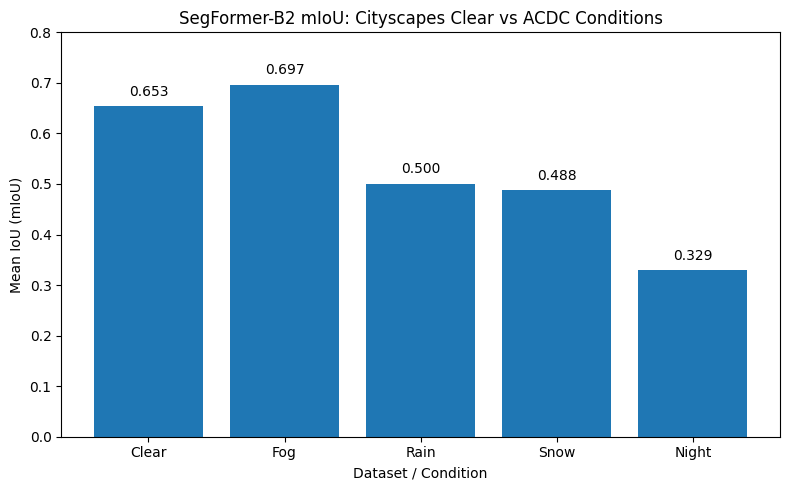

Saved: /content/drive/MyDrive/CV_Project/results/figures/01_condition_miou_comparison.png


In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    miou_df["condition"].str.title(),
    miou_df["mIoU"]
)

plt.ylabel("Mean IoU (mIoU)")
plt.xlabel("Dataset / Condition")

plt.title(
    "SegFormer-B2 mIoU: Cityscapes Clear vs ACDC Conditions"
)

plt.ylim(0, 0.8)

for bar, value in zip(
    bars,
    miou_df["mIoU"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "01_condition_miou_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

Figure 2 — Per-class IoU across Cityscapes and ACDC conditions

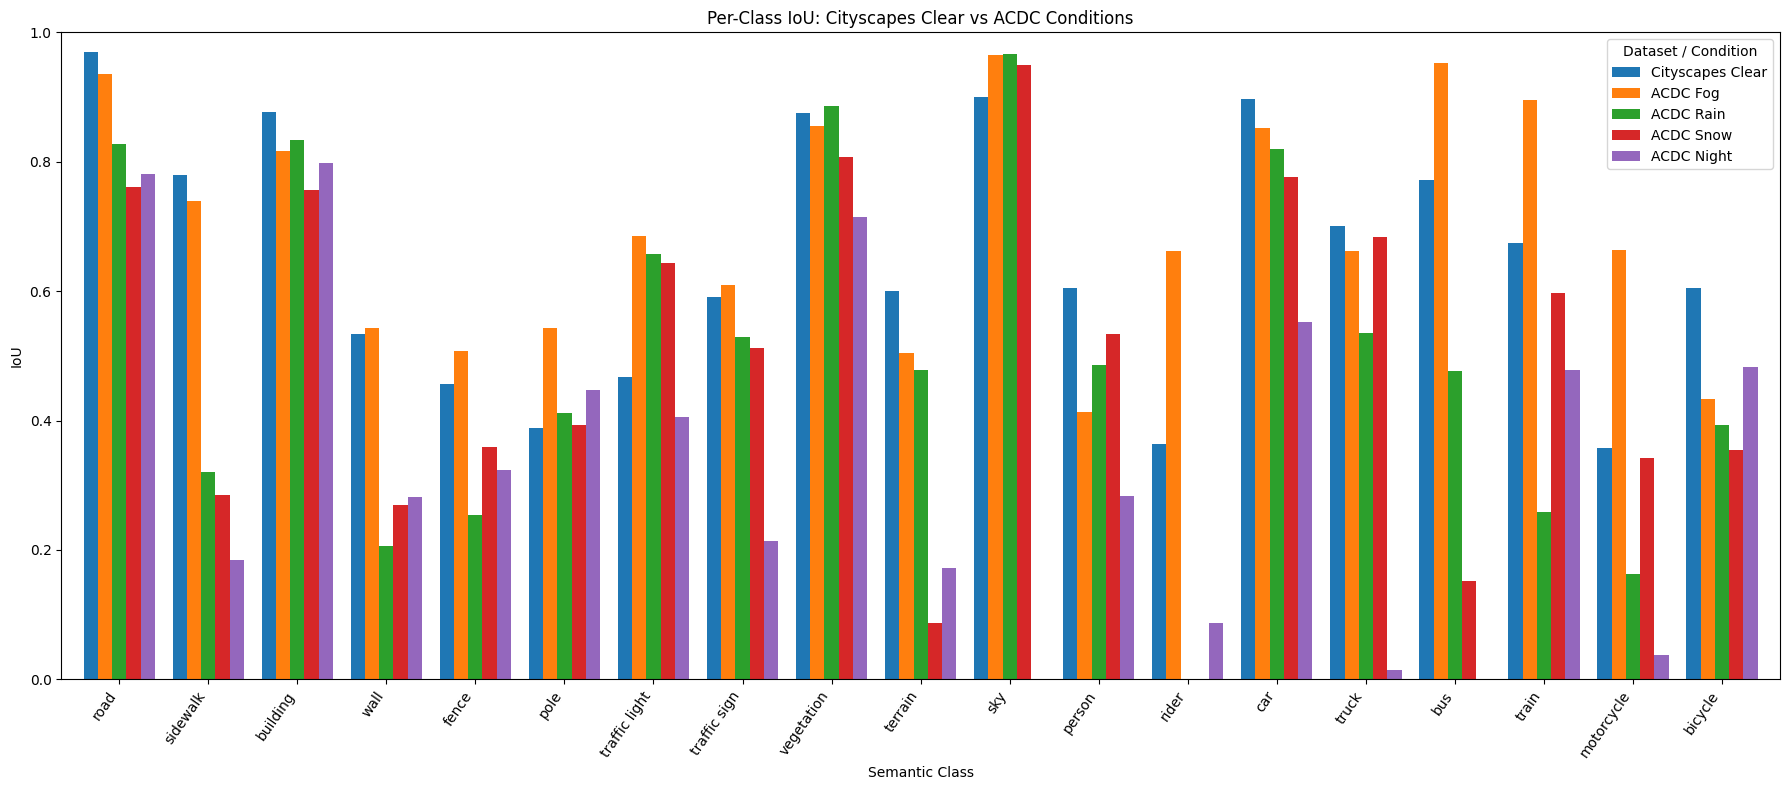

Saved: /content/drive/MyDrive/CV_Project/results/figures/02_per_class_iou_all_conditions.png


In [ ]:
condition_columns = [
    "clear_iou",
    "fog_iou",
    "rain_iou",
    "snow_iou",
    "night_iou"
]

plot_df = combined_df[
    ["class_name"] + condition_columns
].copy()

plot_df = plot_df.set_index(
    "class_name"
)

ax = plot_df.plot(
    kind="bar",
    figsize=(18, 8),
    width=0.8
)

plt.ylabel("IoU")
plt.xlabel("Semantic Class")

plt.title(
    "Per-Class IoU: Cityscapes Clear vs ACDC Conditions"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=55,
    ha="right"
)

plt.legend(
    [
        "Cityscapes Clear",
        "ACDC Fog",
        "ACDC Rain",
        "ACDC Snow",
        "ACDC Night"
    ],
    title="Dataset / Condition"
)

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "02_per_class_iou_all_conditions.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

Figure 3 — Per-class cross-dataset IoU-change heatmap

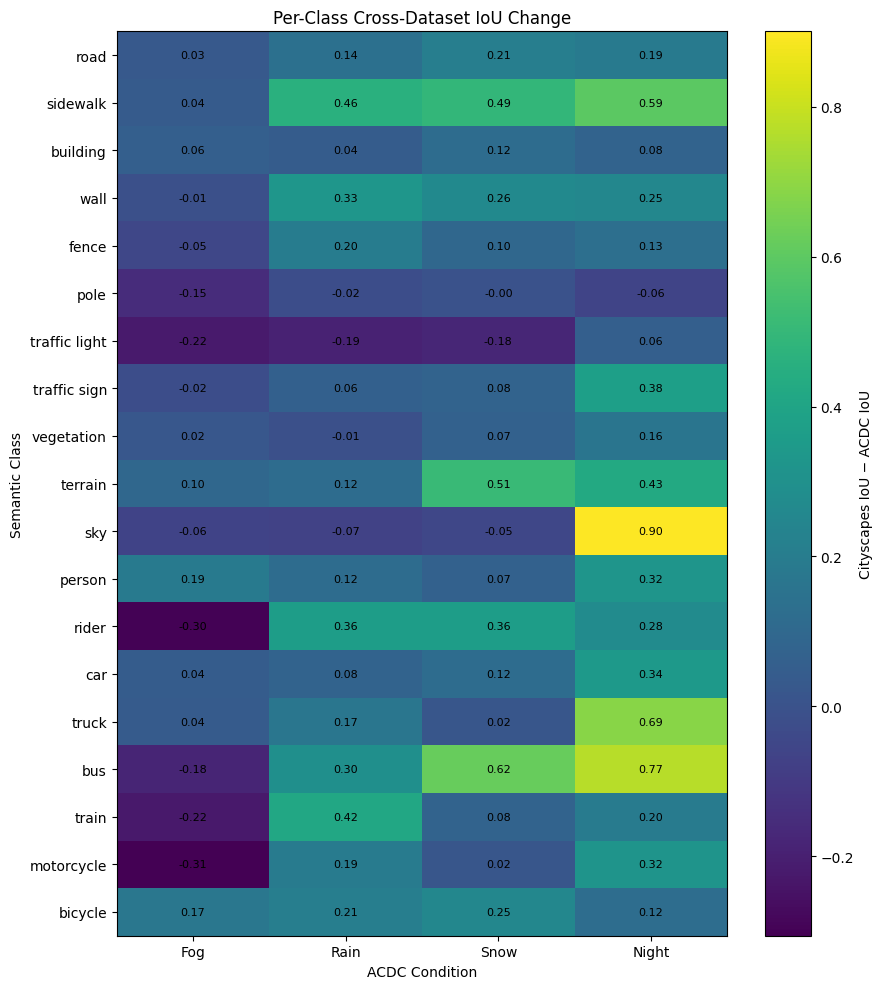

Saved: /content/drive/MyDrive/CV_Project/results/figures/03_per_class_cross_dataset_change_heatmap.png


In [ ]:
heatmap_columns = [
    "fog_change",
    "rain_change",
    "snow_change",
    "night_change"
]

heatmap_data = change_df[
    heatmap_columns
].to_numpy()

fig, ax = plt.subplots(
    figsize=(9, 10)
)

im = ax.imshow(
    heatmap_data,
    aspect="auto"
)

ax.set_xticks(
    range(len(heatmap_columns))
)

ax.set_xticklabels([
    "Fog",
    "Rain",
    "Snow",
    "Night"
])

ax.set_yticks(
    range(len(change_df))
)

ax.set_yticklabels(
    change_df["class_name"]
)

ax.set_xlabel(
    "ACDC Condition"
)

ax.set_ylabel(
    "Semantic Class"
)

ax.set_title(
    "Per-Class Cross-Dataset IoU Change"
)

for i in range(
    heatmap_data.shape[0]
):
    for j in range(
        heatmap_data.shape[1]
    ):
        ax.text(
            j,
            i,
            f"{heatmap_data[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Cityscapes IoU − ACDC IoU"
)

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "03_per_class_cross_dataset_change_heatmap.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

Figure 4 — Classes with the largest average cross-dataset IoU change

In [ ]:
top5 = (
    average_change_df
    .sort_values(
        "average_change",
        ascending=False
    )
    .head(5)
    .copy()
)

display(top5)

,class_name,average_change
0,sidewalk,0.396467
1,bus,0.376671
2,terrain,0.289314
3,truck,0.226486
4,wall,0.208294


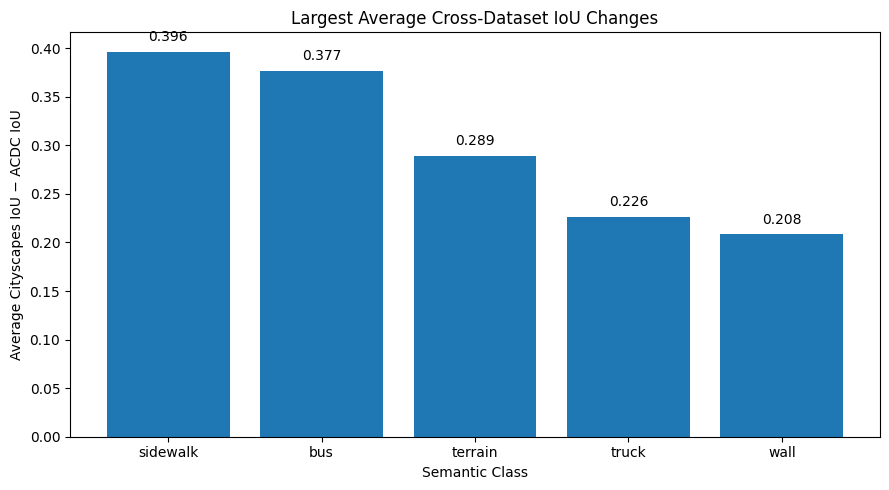

Saved: /content/drive/MyDrive/CV_Project/results/figures/04_top_cross_dataset_change_classes.png


In [ ]:
plt.figure(
    figsize=(9, 5)
)

bars = plt.bar(
    top5["class_name"],
    top5["average_change"]
)

plt.ylabel(
    "Average Cityscapes IoU − ACDC IoU"
)

plt.xlabel(
    "Semantic Class"
)

plt.title(
    "Largest Average Cross-Dataset IoU Changes"
)

for bar, value in zip(
    bars,
    top5["average_change"]
):
    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.008,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "04_top_cross_dataset_change_classes.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

Figure 5 — Condition-specific cross-dataset change of top classes

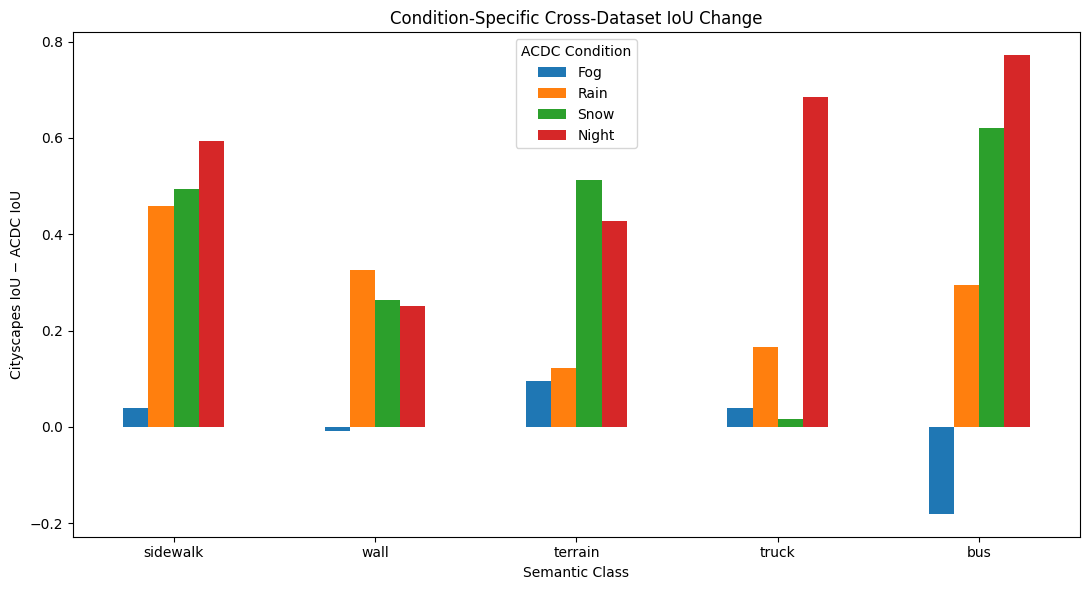

Saved: /content/drive/MyDrive/CV_Project/results/figures/05_top_classes_by_condition.png


In [ ]:
top5_names = (
    top5["class_name"]
    .tolist()
)

top5_condition_df = (
    combined_df[
        combined_df[
            "class_name"
        ].isin(top5_names)
    ]
    .set_index(
        "class_name"
    )
)

ax = top5_condition_df[
    [
        "fog_change",
        "rain_change",
        "snow_change",
        "night_change"
    ]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.ylabel(
    "Cityscapes IoU − ACDC IoU"
)

plt.xlabel(
    "Semantic Class"
)

plt.title(
    "Condition-Specific Cross-Dataset IoU Change"
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "Fog",
        "Rain",
        "Snow",
        "Night"
    ],
    title="ACDC Condition"
)

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "05_top_classes_by_condition.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

Install/import model

In [ ]:
!pip -q install transformers

In [ ]:
import torch
import torch.nn.functional as F
import zipfile

from transformers import (
    AutoImageProcessor,
    SegformerForSemanticSegmentation
)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        torch.cuda.get_device_name(0)
    )

Device: cuda
Tesla T4


Load SegFormer

In [ ]:
MODEL_NAME = (
    "nvidia/"
    "segformer-b2-finetuned-"
    "cityscapes-1024-1024"
)

processor = (
    AutoImageProcessor
    .from_pretrained(MODEL_NAME)
)

model = (
    SegformerForSemanticSegmentation
    .from_pretrained(MODEL_NAME)
)

model = model.to(DEVICE)

model.eval()

print("SegFormer-B2 loaded.")

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

SegFormer-B2 loaded.


Define classes and palette

In [ ]:
CLASS_NAMES = [
    "road",
    "sidewalk",
    "building",
    "wall",
    "fence",
    "pole",
    "traffic light",
    "traffic sign",
    "vegetation",
    "terrain",
    "sky",
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle"
]

NUM_CLASSES = 19
IGNORE_INDEX = 255

Convert mask to color image

In [ ]:
def colorize_mask(mask):

    height, width = mask.shape

    colored = np.zeros(
        (height, width, 3),
        dtype=np.uint8
    )

    for class_id in range(
        NUM_CLASSES
    ):

        colored[
            mask == class_id
        ] = CITYSCAPES_PALETTE[
            class_id
        ]

    # ignored pixels become black
    colored[
        mask == IGNORE_INDEX
    ] = [0, 0, 0]

    return colored

Prediction

In [ ]:
def predict_segmentation(
    image,
    target_shape
):

    inputs = processor(
        images=image,
        return_tensors="pt"
    )

    pixel_values = (
        inputs["pixel_values"]
        .to(DEVICE)
    )

    with torch.inference_mode():

        outputs = model(
            pixel_values=pixel_values
        )

    logits = F.interpolate(
        outputs.logits,
        size=target_shape,
        mode="bilinear",
        align_corners=False
    )

    prediction = (
        logits
        .argmax(dim=1)[0]
        .cpu()
        .numpy()
    )

    return prediction

Local directories

In [ ]:
LOCAL_DATA_ROOT = Path(
    "/content/cv_visualization"
)

LOCAL_DATA_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

CITYSCAPES_RGB_ZIP = (
    DATASETS_DIR
    / "cityscapes"
    / "leftImg8bit.zip"
)

CITYSCAPES_GT_ZIP = (
    DATASETS_DIR
    / "archives"
    / "gtFine_trainvaltest.zip"
)

ACDC_RGB_ZIP = (
    DATASETS_DIR
    / "acdc"
    / "rgb_anon.zip"
)

ACDC_GT_ZIP = (
    DATASETS_DIR
    / "archives"
    / "gt_trainval.zip"
)

Extract one Cityscapes clear example

In [ ]:
CITY_CLEAR_DIR = (
    LOCAL_DATA_ROOT / "clear"
)

CITY_CLEAR_DIR.mkdir(
    parents=True,
    exist_ok=True
)

with zipfile.ZipFile(
    CITYSCAPES_RGB_ZIP,
    "r"
) as z:

    clear_images = [
        name
        for name in z.namelist()

        if name.startswith(
            "leftImg8bit/val/"
        )

        and name.endswith(
            "_leftImg8bit.png"
        )
    ]

    clear_rgb_name = (
        clear_images[0]
    )

    z.extract(
        clear_rgb_name,
        CITY_CLEAR_DIR
    )

print(clear_rgb_name)

leftImg8bit/val/munster/munster_000025_000019_leftImg8bit.png


Extract matching Cityscapes GT

In [ ]:
clear_key = (
    Path(clear_rgb_name)
    .name
    .replace(
        "_leftImg8bit.png",
        ""
    )
)

with zipfile.ZipFile(
    CITYSCAPES_GT_ZIP,
    "r"
) as z:

    matching_clear_gt = [
        name
        for name in z.namelist()

        if "__MACOSX" not in name

        and "/gtFine/val/" in name

        and clear_key in name

        and name.endswith(
            "_gtFine_labelIds.png"
        )
    ][0]

    z.extract(
        matching_clear_gt,
        CITY_CLEAR_DIR
    )

print(matching_clear_gt)

gtFine_trainvaltest/gtFine/val/munster/munster_000025_000019_gtFine_labelIds.png


Cityscapes label mapping

In [ ]:
CITYSCAPES_ID_TO_TRAINID = {
    7: 0,
    8: 1,
    11: 2,
    12: 3,
    13: 4,
    17: 5,
    19: 6,
    20: 7,
    21: 8,
    22: 9,
    23: 10,
    24: 11,
    25: 12,
    26: 13,
    27: 14,
    28: 15,
    31: 16,
    32: 17,
    33: 18
}


def cityscapes_to_trainids(
    mask
):

    output = np.full(
        mask.shape,
        255,
        dtype=np.uint8
    )

    for label_id, train_id in (
        CITYSCAPES_ID_TO_TRAINID
        .items()
    ):

        output[
            mask == label_id
        ] = train_id

    return output

Clear qualitative result

In [ ]:
CITYSCAPES_PALETTE = np.array([
    [128,  64, 128],  # road
    [244,  35, 232],  # sidewalk
    [ 70,  70,  70],  # building
    [102, 102, 156],  # wall
    [190, 153, 153],  # fence
    [153, 153, 153],  # pole
    [250, 170,  30],  # traffic light
    [220, 220,   0],  # traffic sign
    [107, 142,  35],  # vegetation
    [152, 251, 152],  # terrain
    [ 70, 130, 180],  # sky
    [220,  20,  60],  # person
    [255,   0,   0],  # rider
    [  0,   0, 142],  # car
    [  0,   0,  70],  # truck
    [  0,  60, 100],  # bus
    [  0,  80, 100],  # train
    [  0,   0, 230],  # motorcycle
    [119,  11,  32],  # bicycle
], dtype=np.uint8)

print("Palette loaded:", CITYSCAPES_PALETTE.shape)

def colorize_mask(mask):
    height, width = mask.shape

    colored = np.zeros(
        (height, width, 3),
        dtype=np.uint8
    )

    for class_id in range(19):
        colored[mask == class_id] = CITYSCAPES_PALETTE[class_id]

    colored[mask == 255] = [0, 0, 0]

    return colored

Palette loaded: (19, 3)


In [ ]:
clear_image_path = (
    CITY_CLEAR_DIR
    / clear_rgb_name
)

clear_gt_path = (
    CITY_CLEAR_DIR
    / matching_clear_gt
)

clear_image = Image.open(
    clear_image_path
).convert("RGB")

clear_gt_labelids = np.array(
    Image.open(clear_gt_path)
)

clear_gt = (
    cityscapes_to_trainids(
        clear_gt_labelids
    )
)

clear_prediction = (
    predict_segmentation(
        clear_image,
        clear_gt.shape
    )
)

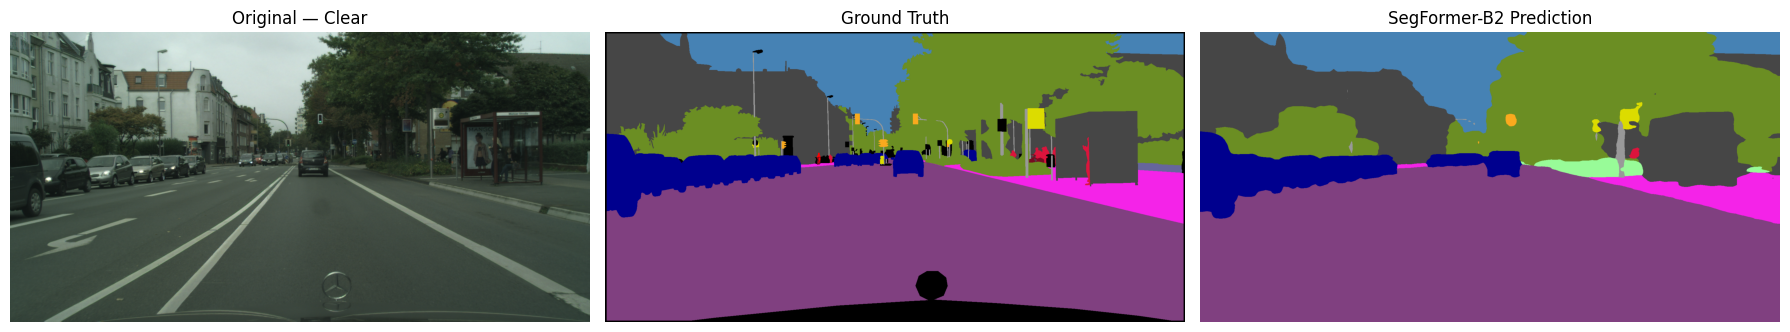

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

axes[0].imshow(
    clear_image
)
axes[0].set_title(
    "Original — Clear"
)
axes[0].axis("off")

axes[1].imshow(
    colorize_mask(clear_gt)
)
axes[1].set_title(
    "Ground Truth"
)
axes[1].axis("off")

axes[2].imshow(
    colorize_mask(
        clear_prediction
    )
)
axes[2].set_title(
    "SegFormer-B2 Prediction"
)
axes[2].axis("off")

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "06_clear_qualitative.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ACDC examples

Extract one ACDC sample, GT, and invalid mask for a condition

In [ ]:
def prepare_acdc_sample(
    condition
):

    condition_dir = (
        LOCAL_DATA_ROOT
        / condition
    )

    condition_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Find one RGB validation image
    with zipfile.ZipFile(
        ACDC_RGB_ZIP,
        "r"
    ) as z:

        rgb_candidates = [
            name
            for name in z.namelist()

            if name.startswith(
                f"rgb_anon/{condition}/val/"
            )

            and name.endswith(
                "_rgb_anon.png"
            )
        ]

        rgb_name = (
            rgb_candidates[0]
        )

        z.extract(
            rgb_name,
            condition_dir
        )

    key = (
        Path(rgb_name)
        .name
        .replace(
            "_rgb_anon.png",
            ""
        )
    )

    # Find corresponding GT and invIds
    with zipfile.ZipFile(
        ACDC_GT_ZIP,
        "r"
    ) as z:

        gt_candidates = [
            name
            for name in z.namelist()

            if (
                f"gt/{condition}/val/"
                in name
            )

            and key in name

            and name.endswith(
                "_gt_labelTrainIds.png"
            )
        ]

        invalid_candidates = [
            name
            for name in z.namelist()

            if (
                f"gt/{condition}/val/"
                in name
            )

            and key in name

            and name.endswith(
                "_gt_invIds.png"
            )
        ]

        gt_name = (
            gt_candidates[0]
        )

        invalid_name = (
            invalid_candidates[0]
        )

        z.extract(
            gt_name,
            condition_dir
        )

        z.extract(
            invalid_name,
            condition_dir
        )

    rgb_path = (
        condition_dir
        / rgb_name
    )

    gt_path = (
        condition_dir
        / gt_name
    )

    invalid_path = (
        condition_dir
        / invalid_name
    )

    return (
        rgb_path,
        gt_path,
        invalid_path
    )

Qualitative visualization helper

For ACDC examples, pixels marked `invIds == 1` are hidden in both the displayed GT and prediction so the qualitative figure follows the same valid-pixel convention as the metric evaluation.

In [ ]:
def visualize_condition(
    condition
):

    (
        rgb_path,
        gt_path,
        invalid_path
    ) = prepare_acdc_sample(
        condition
    )

    image = Image.open(
        rgb_path
    ).convert("RGB")

    ground_truth = np.array(
        Image.open(gt_path)
    )

    invalid_mask = np.array(
        Image.open(invalid_path)
    )

    prediction = (
        predict_segmentation(
            image,
            ground_truth.shape
        )
    )

    ground_truth_display = (
        ground_truth.copy()
    )

    prediction_display = (
        prediction.copy()
    )

    invalid_pixels = (
        invalid_mask == 1
    )

    ground_truth_display[
        invalid_pixels
    ] = 255

    prediction_display[
        invalid_pixels
    ] = 255

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6)
    )

    axes[0].imshow(image)

    axes[0].set_title(
        f"Original — {condition.title()}"
    )

    axes[0].axis("off")

    axes[1].imshow(
        colorize_mask(
            ground_truth_display
        )
    )

    axes[1].set_title(
        "Ground Truth — Valid Pixels"
    )

    axes[1].axis("off")

    axes[2].imshow(
        colorize_mask(
            prediction_display
        )
    )

    axes[2].set_title(
        "Prediction — Valid Pixels"
    )

    axes[2].axis("off")

    plt.tight_layout()

    figure_path = (
        FIGURES_DIR
        / f"07_{condition}_qualitative.png"
    )

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "Saved:",
        figure_path
    )

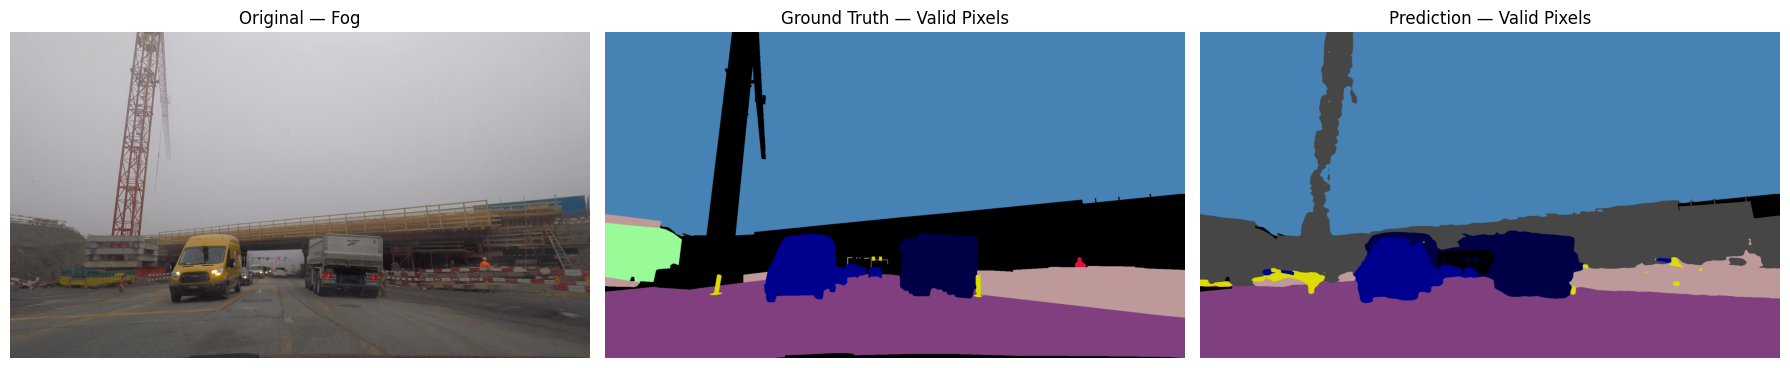

Saved: /content/drive/MyDrive/CV_Project/results/figures/07_fog_qualitative.png


In [ ]:
visualize_condition(
    "fog"
)

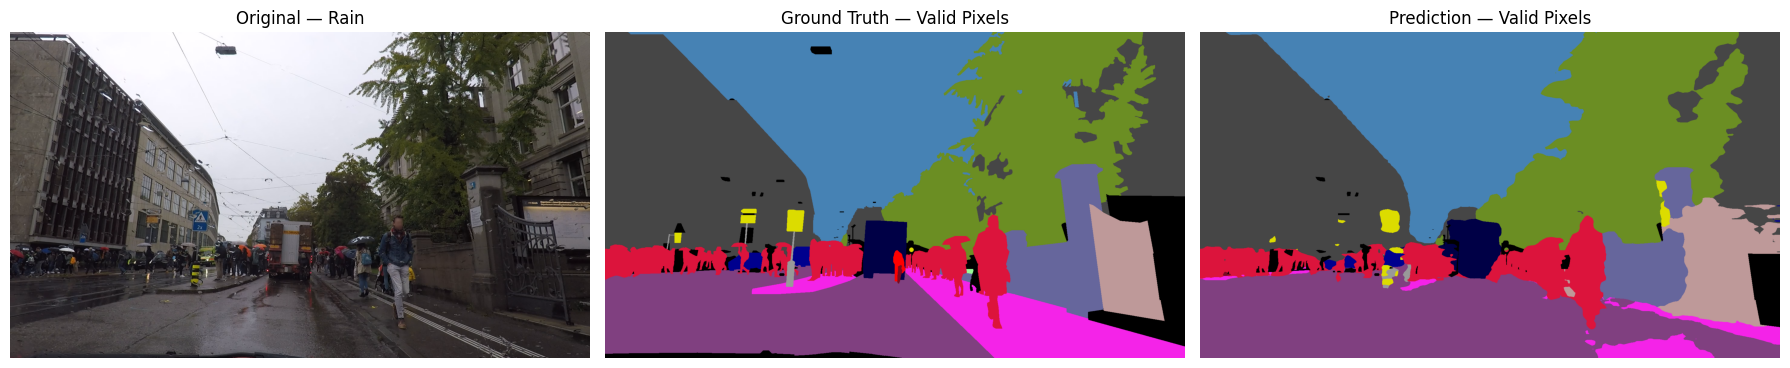

Saved: /content/drive/MyDrive/CV_Project/results/figures/07_rain_qualitative.png


In [ ]:
visualize_condition(
    "rain"
)

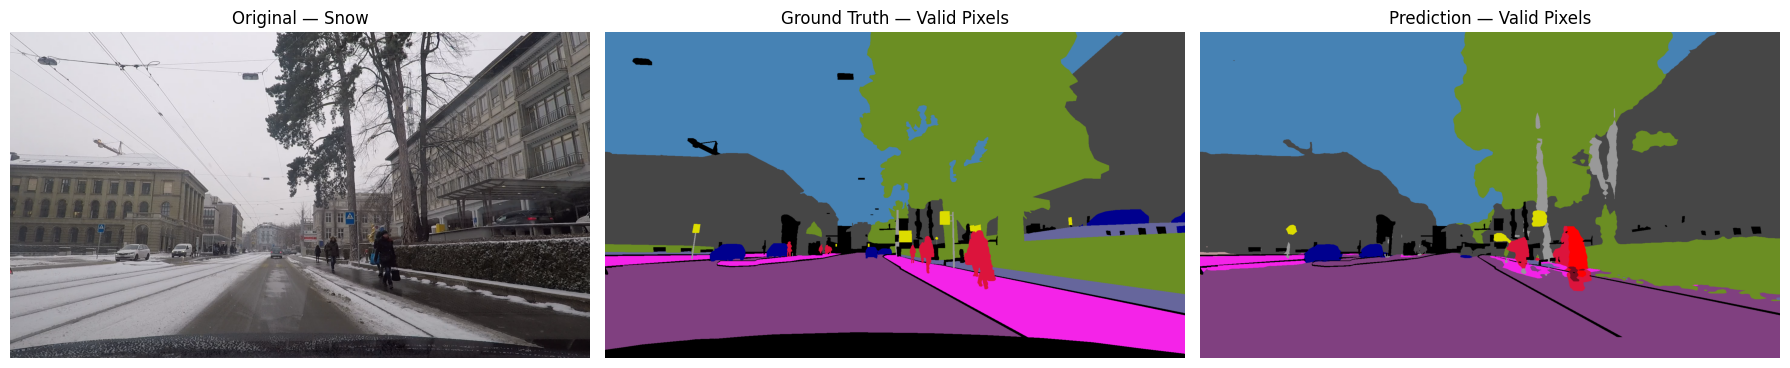

Saved: /content/drive/MyDrive/CV_Project/results/figures/07_snow_qualitative.png


In [ ]:
visualize_condition(
    "snow"
)

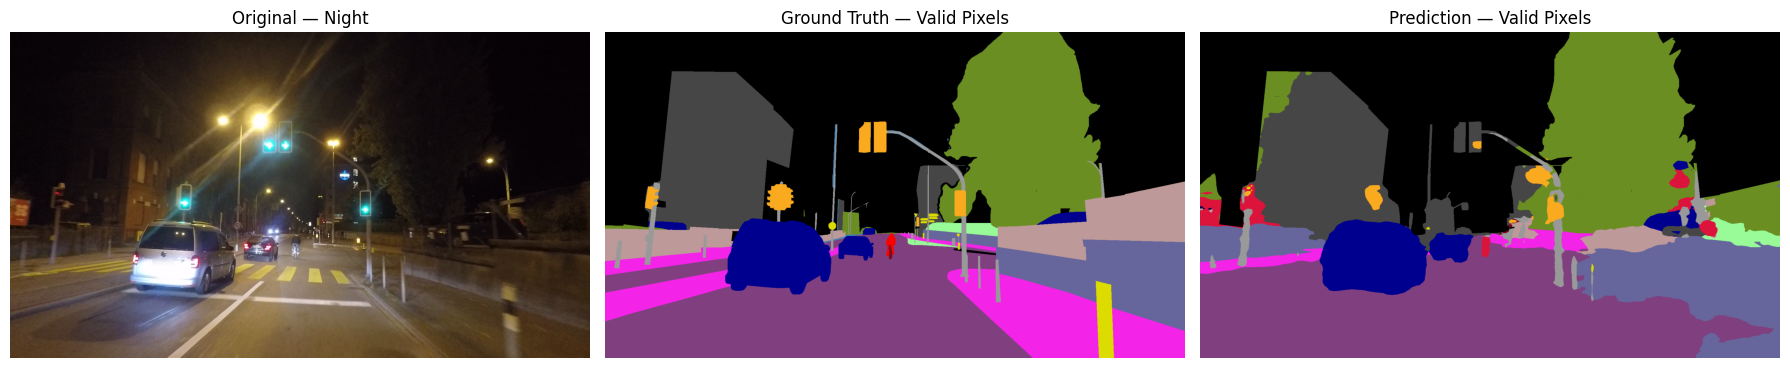

Saved: /content/drive/MyDrive/CV_Project/results/figures/07_night_qualitative.png


In [ ]:
visualize_condition(
    "night"
)

One combined qualitative comparison

In [ ]:
condition_examples = {}

for condition in [
    "fog",
    "rain",
    "snow",
    "night"
]:

    (
        rgb_path,
        gt_path,
        invalid_path
    ) = prepare_acdc_sample(
        condition
    )

    image = Image.open(
        rgb_path
    ).convert("RGB")

    ground_truth = np.array(
        Image.open(gt_path)
    )

    invalid_mask = np.array(
        Image.open(invalid_path)
    )

    prediction = (
        predict_segmentation(
            image,
            ground_truth.shape
        )
    )

    ground_truth_display = (
        ground_truth.copy()
    )

    prediction_display = (
        prediction.copy()
    )

    invalid_pixels = (
        invalid_mask == 1
    )

    ground_truth_display[
        invalid_pixels
    ] = 255

    prediction_display[
        invalid_pixels
    ] = 255

    condition_examples[
        condition
    ] = {
        "image": image,
        "gt": ground_truth_display,
        "prediction": prediction_display,
        "invalid_mask": invalid_mask
    }

print(
    "All condition examples ready."
)

All condition examples ready.


4 × 3 comparison figure

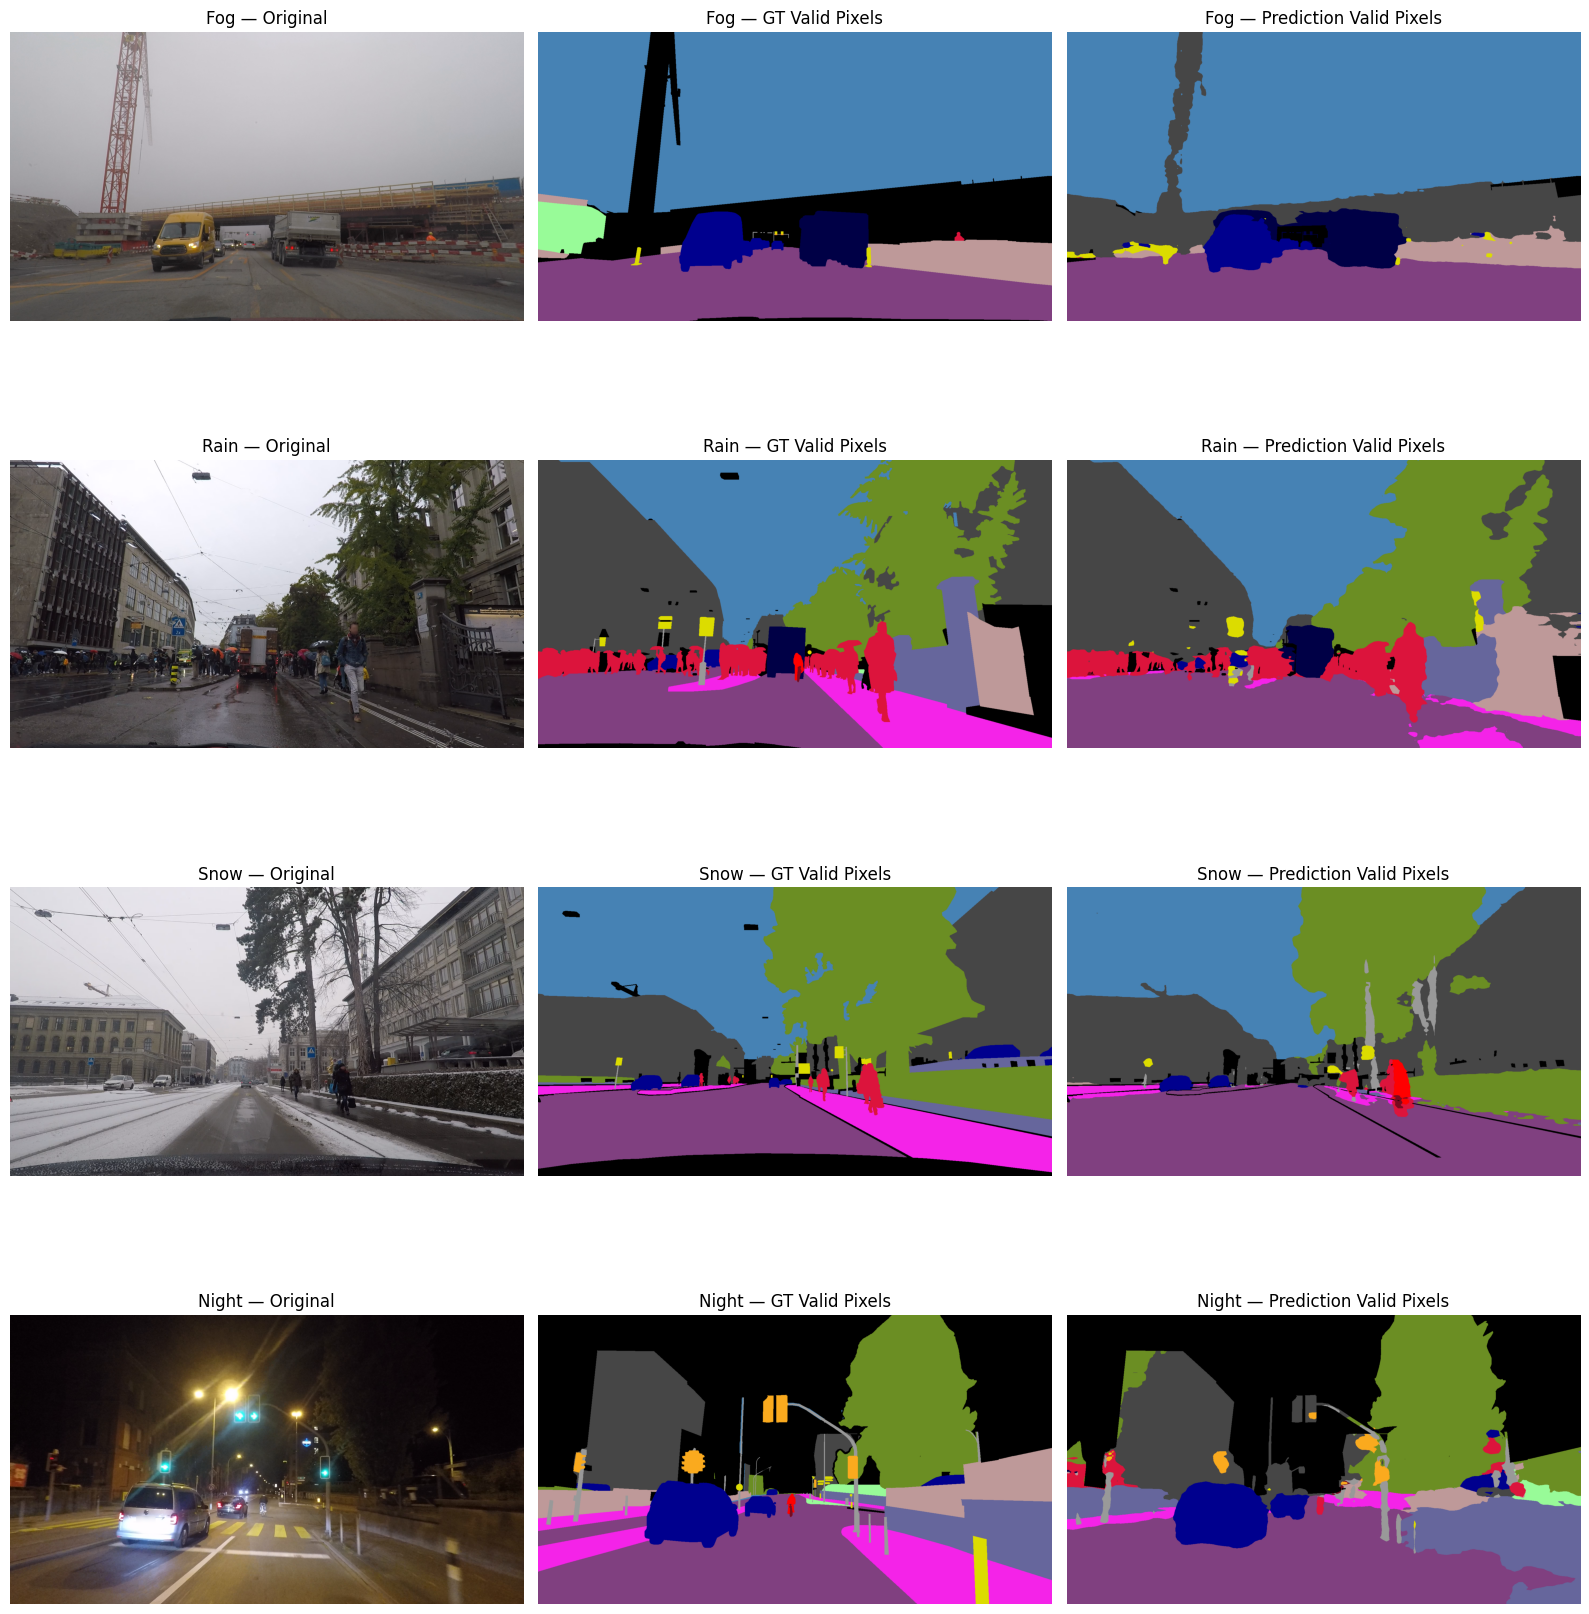

Saved: /content/drive/MyDrive/CV_Project/results/figures/11_all_adverse_qualitative_comparison.png


In [ ]:
comparison_conditions = [
    "fog",
    "rain",
    "snow",
    "night"
]

fig, axes = plt.subplots(
    4,
    3,
    figsize=(16, 18)
)

for row, condition in enumerate(
    comparison_conditions
):

    example = (
        condition_examples[
            condition
        ]
    )

    axes[row, 0].imshow(
        example["image"]
    )

    axes[row, 0].set_title(
        f"{condition.title()} — Original"
    )

    axes[row, 1].imshow(
        colorize_mask(
            example["gt"]
        )
    )

    axes[row, 1].set_title(
        f"{condition.title()} — GT Valid Pixels"
    )

    axes[row, 2].imshow(
        colorize_mask(
            example["prediction"]
        )
    )

    axes[row, 2].set_title(
        f"{condition.title()} — Prediction Valid Pixels"
    )

    for col in range(3):
        axes[row, col].axis(
            "off"
        )

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "11_all_adverse_qualitative_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

## Interpretation Note

The quantitative figures above use corrected ACDC metrics in which `invIds == 1` pixels are excluded.

The Cityscapes-to-ACDC plots are descriptive **cross-dataset comparisons** and do not isolate weather effects.

The ACDC qualitative figures also hide invalid/uncertain pixels so the displayed semantic regions follow the same validity convention as the quantitative evaluation.

## List all saved figures

In [ ]:
saved_figures = sorted(
    FIGURES_DIR.glob("*.png")
)

print(
    f"Total figures saved: "
    f"{len(saved_figures)}"
)

print()

for figure in saved_figures:
    print(
        "✓",
        figure.name
    )

Total figures saved: 13

✓ 01_condition_miou_comparison.png
✓ 02_per_class_iou_all_conditions.png
✓ 03_per_class_cross_dataset_change_heatmap.png
✓ 03_per_class_degradation_heatmap.png
✓ 04_top_cross_dataset_change_classes.png
✓ 04_top_vulnerable_classes.png
✓ 05_top_classes_by_condition.png
✓ 06_clear_qualitative.png
✓ 07_fog_qualitative.png
✓ 07_night_qualitative.png
✓ 07_rain_qualitative.png
✓ 07_snow_qualitative.png
✓ 11_all_adverse_qualitative_comparison.png
